<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/route_02_ollas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/MyDrive/article_OLLAS')
!ls

censo_INEI_manzanas.csv  distritos_LIMA.gpkg  ollas_LIMA.gpkg  vmt
comedores_LIMA.gpkg	 grid_LIMA.gpkg       sjl
dem_LIMA.tif		 manzanas_LIMA.gpkg   slopes_LIMA.tif


In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [4]:
import rasterio
from rasterio.plot import show
import numpy as np

In [5]:
# Each file is assigned to a variable
censo = pd.read_csv("censo_INEI_manzanas.csv", sep=';')
gdf_comedores = gpd.read_file("comedores_LIMA.gpkg")
gdf_ollas = gpd.read_file("ollas_LIMA.gpkg")
gdf_manzanas = gpd.read_file("manzanas_LIMA.gpkg")
altitude = rasterio.open("dem_LIMA.tif")
slopes = rasterio.open('slopes_LIMA.tif')

In [6]:
distritos=gpd.read_file('distritos_LIMA.gpkg')

In [7]:
## merges blocks to census, keeping only the ones with census data
merge_01=gdf_manzanas.merge(censo, on='idmanzana', how='right')

In [8]:
## generates values of altitude and slope per block with census data
manz_centroides=merge_01.geometry.centroid
lista_coord=[(x,y) for x,y in zip(manz_centroides.geometry.x, manz_centroides.geometry.y)]

merge_01['slope'] = [cc[0] for cc in slopes.sample(lista_coord)]
merge_01['altitude']=[cc[0] for cc in altitude.sample(lista_coord)]
merge_01.loc[merge_01.slope<=0,'slope']=0

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

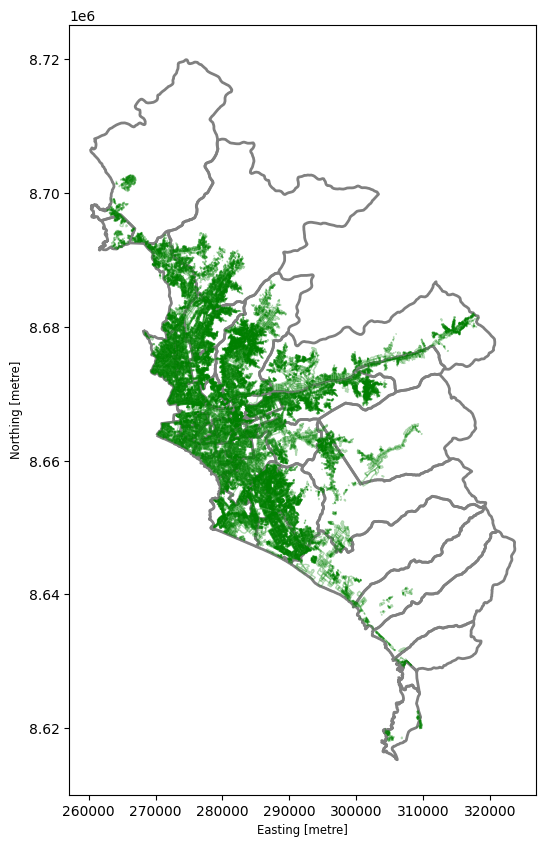

In [9]:
axis=distritos.boundary.plot(figsize=(10,10), linewidth=2, color='grey')
merge_01.boundary.plot(ax=axis, color='green', linewidth=1, alpha=0.3)

In [9]:
## join_01 genera la distancia lineal a comedor más cercano desde cada Olla para comparar con distancia caminando
join_01=gpd.sjoin_nearest(gdf_ollas,gdf_comedores, how='left', distance_col='dist_linear')[['fid_olla',
            'o_dist_near_comedor','dist_linear','geometry']].rename(columns={'o_dist_near_comedor':'dist_walk'})
join_01.describe(include='all').transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fid_olla,2041.0,NaN,NaN,NaN,2145.792749,589.763371,703.0,1636.0,2146.0,2656.0,3166.0
dist_walk,2041.0,NaN,NaN,NaN,622.900704,856.384318,5.828028,237.476159,405.795481,720.983968,19332.932936
dist_linear,2041.0,NaN,NaN,NaN,393.721357,604.777368,2.038423,138.66817,241.048515,441.167321,13042.989478
geometry,2041,2041,POINT (289224.08869567723 8675656.85142984),1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


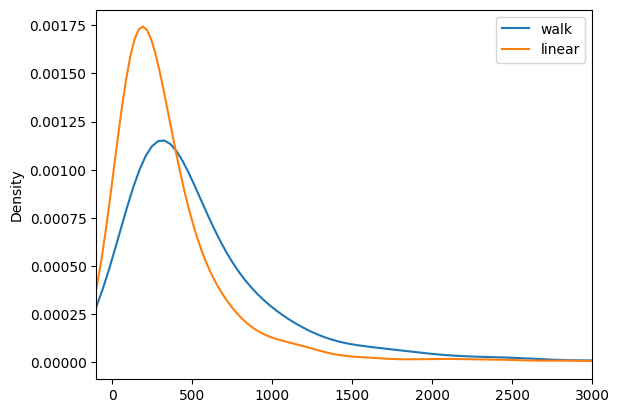

In [10]:
axis=join_01.dist_walk.plot(kind='kde', xlim=(-100,3000),label='walk')
join_01.dist_linear.plot(kind='kde', ax=axis, label='linear')
plt.legend()

In [22]:
### join_02 identifica la manzana más cercana a cada Olla (distancia==0 implica Olla está en manzana)
join_02=gpd.sjoin_nearest(join_01,merge_01,distance_col='dist_block', how='left')
join_02=join_02[['idmanzana','fid_olla', 'dist_walk', 'dist_linear', 'dist_block']]
join_02.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
fid_olla,2041.0,2145.792749,589.763371,703.000000,1636.000000,2146.000000,2656.000000,3166.000000
dist_walk,2041.0,622.900704,856.384318,5.828028,237.476159,405.795481,720.983968,19332.932936
dist_linear,2041.0,393.721357,604.777368,2.038423,138.668170,241.048515,441.167321,13042.989478
dist_block,2041.0,53.978600,399.228188,0.000000,0.000000,4.641014,23.887934,7485.233300


In [23]:
### keep Ollas with blocks at least up to 100 meters of distance
join_02=join_02[join_02.dist_block<=100]

In [24]:
join_02.describe(include='all').transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
idmanzana,1897,1727,15013300202039A,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fid_olla,1897.0,NaN,NaN,NaN,2149.67106,592.073303,703.0,1642.0,2156.0,2665.0,3166.0
dist_walk,1897.0,NaN,NaN,NaN,536.368014,588.001922,5.828028,228.24543,375.607188,647.172982,9873.514453
dist_linear,1897.0,NaN,NaN,NaN,337.040432,426.446287,2.038423,132.646595,226.118427,398.064193,8286.256782
dist_block,1897.0,NaN,NaN,NaN,12.495072,19.319216,0.0,0.0,3.422508,16.51668,98.922187


In [25]:
# Calculate the count of ollas (points) per block in join_02
ollas_count=join_02.groupby('idmanzana', as_index=False).agg({'fid_olla':'count'}).rename(columns={'fid_olla':'ollas_count'})

In [26]:
join_02=join_02.merge(ollas_count, on='idmanzana', how='left')

In [27]:
join_02.columns

Index(['idmanzana', 'fid_olla', 'dist_walk', 'dist_linear', 'dist_block',
       'ollas_count'],
      dtype='object')

In [30]:
### integrates blocks with Ollas assigned (<100 meters of distance)
merge_02=merge_01.merge(join_02,on='idmanzana', how='left')

In [32]:
print(f"Shape of merge_02 before dropping duplicates: {merge_02.shape}")
merge_02 = merge_02.drop_duplicates(subset=['idmanzana'])
print(f"Shape of merge_02 after dropping duplicates: {merge_02.shape}")

Shape of merge_02 before dropping duplicates: (61014, 32)
Shape of merge_02 after dropping duplicates: (60844, 32)


In [34]:
import geopandas as gpd

# Calculate the linear distance in meters from each block in 'merge_02' to the nearest 'gdf_comedores' point
nearest_comedores = gpd.sjoin_nearest(
    merge_02,
    gdf_comedores,
    how='left',
    distance_col='dist_to_comedor'
)

# If a block is equidistant to multiple comedores, drop duplicates to keep one entry per 'idmanzana'
nearest_comedores_unique = nearest_comedores.drop_duplicates(subset=['idmanzana'])

# Merge the distance back into 'merge_02'
merge_02 = merge_02.merge(
    nearest_comedores_unique[['idmanzana', 'dist_to_comedor']],
    on='idmanzana',
    how='left'
)

# Display summary statistics of the new variable
print(merge_02['dist_to_comedor'].describe())

count    60844.000000
mean       382.220678
std        562.007047
min          0.000000
25%         74.852282
50%        174.518816
75%        424.332535
max       8202.873209
Name: dist_to_comedor, dtype: float64


In [35]:
import numpy as np

# Create 'distance' in 'merge_02': 'dist_block' if 'dist_walk' is NaN, otherwise 'dist_walk'
merge_02['distance'] = np.where(merge_02['dist_walk'].isna(), merge_02['dist_to_comedor'], merge_02['dist_walk'])

# Display summary of the newly created variable
print(merge_02['distance'].describe())

count    60844.000000
mean       389.233002
std        566.369268
min          0.000000
25%         76.562855
50%        179.893455
75%        438.445038
max       9873.514453
Name: distance, dtype: float64


In [38]:
import geopandas as gpd

# Convert merge_02 to a GeoDataFrame using the 'geometry' column
# merge_02 = gpd.GeoDataFrame(merge_02, geometry='geometry', crs=merge_01.crs)

# Calculate the area in square kilometers
merge_02['area_km2'] = merge_02.geometry.area / 1000000

In [39]:
merge_02['has_olla']=0
merge_02.loc[merge_02.ollas_count>0,'has_olla']=1

In [40]:
merge_02.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
viviendas,60844.0,38.014677,46.032215,3.000000,16.000000,27.000000,45.000000,5275.000000
poblacion,60844.0,130.125288,138.849194,30.000000,53.000000,98.000000,168.000000,13462.000000
t_agua,60844.0,0.205120,0.284630,0.000000,0.000000,0.071429,0.272727,1.000000
t_luz,60844.0,0.039138,0.126399,0.000000,0.000000,0.000000,0.000000,1.000000
t_pared,60844.0,0.158664,0.235111,0.000000,0.000000,0.041667,0.222222,1.000000
t_techo,60844.0,0.252087,0.257118,0.000000,0.045455,0.159465,0.400000,1.000000
t_piso,60844.0,0.069771,0.115109,0.000000,0.000000,0.010526,0.097561,1.000000
t_carbon,60844.0,0.013980,0.045162,0.000000,0.000000,0.000000,0.000000,0.928571
t_lena,60844.0,0.024528,0.067732,0.000000,0.000000,0.000000,0.000000,1.000000
t_nococin,60844.0,0.020404,0.036702,0.000000,0.000000,0.000000,0.031746,0.500000


In [41]:
import numpy as np
from shapely.geometry import Polygon
import geopandas as gpd

# Get total bounds of the merge_blocks_census GeoDataFrame
xmin, ymin, xmax, ymax = merge_02.total_bounds

# Define cell size (400 meters)
cell_size = 400.0

# Create grid cell geometries
x_coords = np.arange(xmin, xmax, cell_size)
y_coords = np.arange(ymin, ymax, cell_size)

grid_cells = []
for x in x_coords:
    for y in y_coords:
        # Form a 400x400m square polygon
        grid_cells.append(Polygon([
            (x, y),
            (x + cell_size, y),
            (x + cell_size, y + cell_size),
            (x, y + cell_size)
        ]))

# Create a GeoDataFrame from the grid cell geometries
grid_400 = gpd.GeoDataFrame(geometry=grid_cells, crs=merge_02.crs)
grid_400['id_grid_400'] = range(len(grid_400))

print(f"Created grid_400 with {len(grid_400)} cells.")

Created grid_400 with 29468 cells.


In [42]:
import geopandas as gpd

# Perform a spatial join to keep only grid cells that intersect with the census blocks
grid_400_intersected = gpd.sjoin(grid_400, merge_02[['geometry']], how='inner', predicate='intersects')

# Since multiple blocks can intersect a single grid cell, keep unique grid cells
grid_400_cleaned = grid_400[grid_400['id_grid_400'].isin(grid_400_intersected['id_grid_400'])].copy()

# Update the main variable grid_400
grid_400 = grid_400_cleaned

print(f"Corrected grid_400: now contains {len(grid_400)} cells that intersect with 'merge_02'.")

Corrected grid_400: now contains 6026 cells that intersect with 'merge_02'.


In [43]:
# convertimos la geometria de manzanas a puntos para relacionarla con grid
merge_02['geometry'] = merge_02.geometry.centroid

In [44]:
### relacionamos cada manzana con la celda donde caen los puntos
join_03=gpd.sjoin(grid_400,merge_02, how='left', predicate='intersects')

In [45]:
join_03.columns

Index(['geometry', 'id_grid_400', 'index_right', 'idmanzana', 'ubigeo',
       'nombdist', 'nombcccpp', 'tipo', 'distrito', 'viviendas', 'poblacion',
       't_agua', 't_luz', 't_pared', 't_techo', 't_piso', 't_carbon', 't_lena',
       't_nococin', 't_jhsolte', 't_jhmigra', 't_jhnoesp', 't_jhnotrab',
       't_child5', 't_adulmay', 't_jh30', 't_jh70', 'slope', 'altitude',
       'fid_olla', 'dist_walk', 'dist_linear', 'dist_block', 'ollas_count',
       'dist_to_comedor', 'distance', 'area_km2', 'has_olla'],
      dtype='object')

In [46]:
group_02=join_03.groupby('id_grid_400', as_index=False).agg({'has_olla':'max', 'distance':'mean',
       'distrito':'first', 'viviendas':'sum', 'poblacion':'sum', 't_agua':'mean', 't_luz':'mean', 't_pared':'mean',
       't_techo':'mean', 't_piso':'mean', 't_carbon':'mean', 't_lena':'mean', 't_nococin':'mean', 't_jhsolte':'mean',
       't_jhmigra':'mean', 't_jhnoesp':'mean', 't_jhnotrab':'mean', 't_child5':'mean', 't_adulmay':'mean',
       't_jh30':'mean', 't_jh70':'mean', 'slope':'mean', 'altitude':'mean', 'area_km2':'sum', 'ollas_count':'sum'})
#

In [47]:
grid_merge=grid_400.merge(group_02, on='id_grid_400', how='left')

In [48]:
grid_merge.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 6026 entries, 0 to 6025
Data columns (total 27 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   geometry     6026 non-null   geometry
 1   id_grid_400  6026 non-null   int64   
 2   has_olla     5273 non-null   float64 
 3   distance     5273 non-null   float64 
 4   distrito     5273 non-null   object  
 5   viviendas    6026 non-null   float64 
 6   poblacion    6026 non-null   float64 
 7   t_agua       5273 non-null   float64 
 8   t_luz        5273 non-null   float64 
 9   t_pared      5273 non-null   float64 
 10  t_techo      5273 non-null   float64 
 11  t_piso       5273 non-null   float64 
 12  t_carbon     5273 non-null   float64 
 13  t_lena       5273 non-null   float64 
 14  t_nococin    5273 non-null   float64 
 15  t_jhsolte    5273 non-null   float64 
 16  t_jhmigra    5273 non-null   float64 
 17  t_jhnoesp    5273 non-null   float64 
 18  t_jhnotrab   5273 no

In [49]:
base_clean=grid_merge.dropna()

In [50]:
base_clean['area_cell_km2']=base_clean.geometry.area/1000000

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [51]:
base_clean.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
id_grid_400,5273.0,11873.382894,5.448724e+03,197.00000,7809.000000,11146.000000,14972.000000,29203.000000
has_olla,5273.0,0.186042,3.891775e-01,0.00000,0.000000,0.000000,0.000000,1.000000
distance,5273.0,574.797019,7.664084e+02,0.00000,122.470816,281.731596,700.494291,9873.514453
viviendas,5273.0,438.643087,4.052987e+02,5.00000,101.000000,329.000000,686.000000,5508.000000
poblacion,5273.0,1501.487389,1.398893e+03,30.00000,292.000000,1090.000000,2442.000000,14305.000000
t_agua,5273.0,0.283417,2.775536e-01,0.00000,0.075000,0.150630,0.470085,1.000000
t_luz,5273.0,0.064949,1.375455e-01,0.00000,0.000000,0.004902,0.056361,1.000000
t_pared,5273.0,0.187532,2.175870e-01,0.00000,0.016322,0.091036,0.304348,1.000000
t_techo,5273.0,0.274466,2.347092e-01,0.00000,0.070503,0.208497,0.453185,1.000000
t_piso,5273.0,0.083808,1.113953e-01,0.00000,0.003710,0.038138,0.128575,1.000000


In [52]:
base_clean['pop_dens_01']=base_clean.poblacion/base_clean.area_km2
base_clean['pop_dens_02']=base_clean.poblacion/base_clean.area_cell_km2

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [53]:
top_1_percentile_01 = base_clean['pop_dens_01'].quantile(0.99)
top_1_percentile_02 = base_clean['pop_dens_02'].quantile(0.99)

In [54]:
base_clean=base_clean[(base_clean['pop_dens_01'] < top_1_percentile_01) & (base_clean['pop_dens_02'] < top_1_percentile_02)]
# print(f"New shape of base_clean after dropping top 1%: {base_clean.shape}")
# display(base_clean.head())

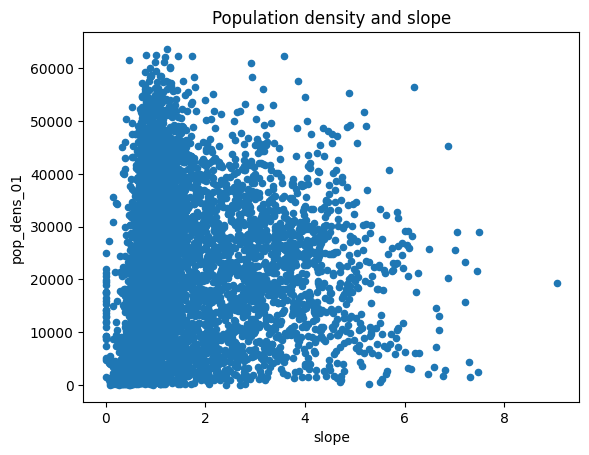

In [55]:
## Check some bivariate relations for some variables
base_clean.plot.scatter(x='slope',y='pop_dens_01')
plt.title("Population density and slope")
plt.show()

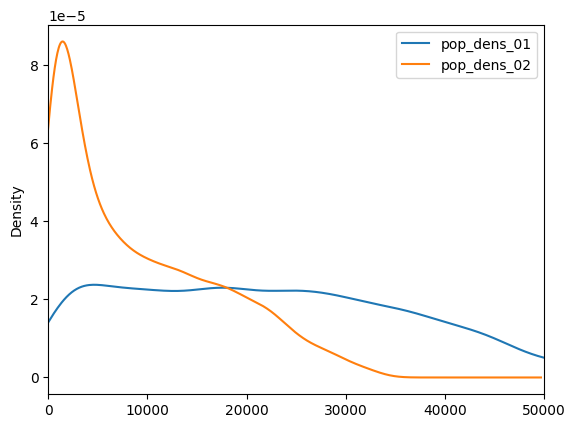

In [56]:
axis=base_clean.pop_dens_01.plot(kind='kde', xlim=(0,50000), label='pop_dens_01')
base_clean.pop_dens_02.plot(kind='kde', ax=axis, label='pop_dens_02')
axis.legend()

In [57]:
### Districts to exclude from the analysis (middle class without Ollas and Comoedores)
exclude=['SAN MIGUEL', 'PUEBLO LIBRE',
       'MAGDALENA DEL MAR', 'BREÑA',
       'SAN ISIDRO', 'JESUS MARIA', 'MIRAFLORES', 'LINCE',
       'SURQUILLO', 'BARRANCO', 'SANTIAGO DE SURCO', 'SAN LUIS',
       'SAN BORJA', 'LA MOLINA', 'SANTA MARIA DEL MAR','MAGDALENA VIEJA',
         'SAN BARTOLO', 'PUNTA NEGRA', 'PUCUSANA', 'PUNTA HERMOSA']

In [58]:
base_clean=base_clean[~base_clean['distrito'].isin(exclude)]

In [59]:
base_clean.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
id_grid_400,4310.0,11919.816473,5.578969e+03,197.000000,7766.250000,11384.500000,15389.500000,29203.000000
has_olla,4310.0,0.219954,4.142630e-01,0.000000,0.000000,0.000000,0.000000,1.000000
distance,4310.0,389.332998,4.811526e+02,0.000000,109.484383,225.660965,482.729627,4987.680090
viviendas,4310.0,395.867285,3.529249e+02,5.000000,92.000000,292.500000,632.750000,1892.000000
poblacion,4310.0,1435.979118,1.326033e+03,30.000000,273.250000,981.000000,2407.500000,5309.000000
t_agua,4310.0,0.305800,2.896147e-01,0.000000,0.072490,0.163220,0.549250,1.000000
t_luz,4310.0,0.072149,1.361760e-01,0.000000,0.000000,0.009652,0.076037,1.000000
t_pared,4310.0,0.215048,2.195428e-01,0.000000,0.029834,0.132542,0.349408,1.000000
t_techo,4310.0,0.316399,2.264830e-01,0.000000,0.115257,0.277742,0.486752,1.000000
t_piso,4310.0,0.096523,1.101275e-01,0.000000,0.012675,0.059692,0.146521,1.000000


In [60]:
base_clean.crs

<Projected CRS: EPSG:32718>
Name: WGS 84 / UTM zone 18S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 78°W and 72°W, southern hemisphere between 80°S and equator, onshore and offshore. Argentina. Brazil. Chile. Colombia. Ecuador. Peru.
- bounds: (-78.0, -80.0, -72.0, 0.0)
Coordinate Operation:
- name: UTM zone 18S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [62]:
### Descriptive statistics for Cells with/without Olla
descrip1=base_clean.groupby('has_olla').agg({'pop_dens_02':'mean',
                                      'distance':'mean',
                                      'altitude':'mean'})
descrip2=base_clean.groupby('has_olla').agg({'t_agua':'mean',
                                              't_piso':'mean',
                                              'slope':'mean'})
(descrip1,descrip2)

(          pop_dens_02    distance    altitude
 has_olla                                     
 0.0       9293.337299  396.605717  253.233449
 1.0       7845.450949  363.540932  352.972891,
             t_agua    t_piso     slope
 has_olla                              
 0.0       0.271697  0.078296  1.510600
 1.0       0.426740  0.161163  2.859597)

In [63]:
## We can estimate a PROBIT MODEL of the probability of each cell having 1 or more Ollas
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
import numpy as np

In [64]:
## It is a good practice to transform some variables to logs (better statistical behavios)
base_clean['log_pob']=np.log(np.maximum(base_clean["pop_dens_02"], 1))
base_clean['log_altitude']=np.log(np.maximum(base_clean["altitude"], 1))
base_clean['log_distance']=np.log(np.maximum(base_clean["distance"], 1))

In [69]:
formula = ("has_olla ~ log_distance + "
    "t_agua + "
    "t_piso + "
    "slope + "
    "log_altitude + "
    "log_pob")

In [70]:
# PROBIT
probit_model = smf.probit(formula=formula, data=base_clean).fit(cov_type="HC1")
print(probit_model.summary())

Optimization terminated successfully.
         Current function value: 0.401842
         Iterations 6
                          Probit Regression Results                           
Dep. Variable:               has_olla   No. Observations:                 4310
Model:                         Probit   Df Residuals:                     4303
Method:                           MLE   Df Model:                            6
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.2373
Time:                        16:52:37   Log-Likelihood:                -1731.9
converged:                       True   LL-Null:                       -2270.7
Covariance Type:                  HC1   LLR p-value:                1.490e-229
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -6.9538      0.411    -16.925      0.000      -7.759      -6.149
log_distance     0.0751

In [72]:
import pysal.lib as lib
import statsmodels.formula.api as smf
import numpy as np

# 1. Create a spatial weights matrix using 8-nearest neighbors based on cell centroids
w = lib.weights.KNN.from_dataframe(base_clean, k=8)
w.transform = 'R'  # Row-standardize weights

# 2. Prepare the SLX dataset by calculating spatially lagged independent variables
slx_data = base_clean.copy()
independent_vars = ['log_distance', 't_agua', 't_piso', 'slope', 'log_altitude', 'log_pob']

for var in independent_vars:
    slx_data[f'lag_{var}'] = lib.weights.lag_spatial(w, base_clean[var])

# 3. Construct the model formula
slx_rhs = ' + '.join(independent_vars + [f'lag_{v}' for v in independent_vars])
slx_formula = f"ollas_count ~ {slx_rhs}"

# 4. Estimate the SLX Poisson Model
print("=== SLX POISSON MODEL ===")
slx_poisson = smf.poisson(formula=slx_formula, data=slx_data).fit(cov_type="HC1")
print(slx_poisson.summary())

# 5. Estimate the SLX Negative Binomial Model
print("\n=== SLX NEGATIVE BINOMIAL MODEL ===")
slx_negbin = smf.negativebinomial(formula=slx_formula, data=slx_data).fit(cov_type="HC1", maxiter=100)
print(slx_negbin.summary())

/usr/local/lib/python3.13/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


=== SLX POISSON MODEL ===
Optimization terminated successfully.
         Current function value: 0.674640
         Iterations 7
                          Poisson Regression Results                          
Dep. Variable:            ollas_count   No. Observations:                 4310
Model:                        Poisson   Df Residuals:                     4297
Method:                           MLE   Df Model:                           12
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.3352
Time:                        16:54:03   Log-Likelihood:                -2907.7
converged:                       True   LL-Null:                       -4374.0
Covariance Type:                  HC1   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -7.8071      0.788     -9.912      0.000      -9.3

In [73]:
# Ensure all layers have the same CRS as base_clean
target_crs = base_clean.crs

gdf_ollas_aligned = gdf_ollas.to_crs(target_crs)
gdf_comedores_aligned = gdf_comedores.to_crs(target_crs)

# Save all three as layers in a single GeoPackage file
gpkg_filename = 'ollas_analysis_layers.gpkg'

print("Saving 'base_clean' layer...")
base_clean.to_file(gpkg_filename, layer='base_clean', driver='GPKG')

print("Saving 'gdf_ollas' layer...")
gdf_ollas_aligned.to_file(gpkg_filename, layer='gdf_ollas', driver='GPKG')

print("Saving 'gdf_comedores' layer...")
gdf_comedores_aligned.to_file(gpkg_filename, layer='gdf_comedores', driver='GPKG')

print(f"Successfully saved all layers to {gpkg_filename}!")

Saving 'base_clean' layer...
Saving 'gdf_ollas' layer...
Saving 'gdf_comedores' layer...
Successfully saved all layers to ollas_analysis_layers.gpkg!
